# 05. 오늘 경기 예측 — 매일 도는 파이프라인을 한 칸씩

안녕하세요! **KBO 승패 예측 프로젝트의 다섯 번째 이야기**예요.
01~04번에서 데이터를 모으고, 피처를 만들고, 승패 모델을 학습하고, 선수 유형을 나눴어요. 이번에는 그 재료가 **실제로 매일 어떻게 쓰이는지**를 봐요. GitHub Actions가 하루 두 번(09:07 · 17:07 KST) 돌리는 `scripts/run_pipeline.py`가 하는 일을, **"오늘" 하루를 고정해서** 노트북에서 똑같이 따라가요.

### 이 노트북이 하는 일
- **"오늘"을 2026-10-29로 고정해요.** 플레이오프 3차전 삼성 @ KIA가 있는 날이고, 그날 받아 둔 **예고 선발**이 저장소에 있어요. 그래서 인터넷 없이도 그날의 예측을 그대로 다시 만들 수 있어요.
- 그날 경기 직전의 **리그 상태**(팀·투수 누적 기록)를 만들고, 두 팀을 나란히 비교해요.
- 예고 선발 두 명의 기록과 **직전 시즌 투수 유형**(04번)을 붙여요.
- 승패 모델(라이브 `v0.2`)로 **KIA가 이길 확률**을 내고, 확률을 움직인 **요인 상위 5개**를 막대로 봐요.
- **전망(outlook)** 카드: 남은 시리즈를 **몬테카를로 시뮬레이션**으로 1만 번 굴려 시리즈 승리 확률과 "가장 흔한 결말"을 구해요. 오늘 경기는 예고 선발을 아는 5번의 확률로, 그 뒤 경기는 선발 없는 팀 모델로 굴려요. 정확한 계산과도 비교해요.
- **되감기(rewind)** 모드: 이미 끝난 2026 정규시즌의 하루(2026-09-01)를 열어 "그날 모델은 이렇게 예측했고, 결과는 이랬다"를 보고, 시즌 내내의 **누적 적중률**을 그려요.
- **라이브 기록**(`history.csv`): 경기 전에 공개한 예측이 실제로 맞았는지 모델 버전별로 세요.
- 마지막으로 노트북의 결과가 **파이프라인이 만든 파일과 완전히 같은지** `assert`로 확인해요(9번).

### 왜 필요한가요?
모델을 한 번 학습하고 끝내면 "그래서 오늘 경기는요?"에 답할 수 없어요. 이 프로젝트는 **매일 자동으로** 경기 일정·예고 선발을 받아 예측을 공개하고(`latest.json`), 경기가 끝나면 맞았는지 기록해요(`history.csv`). 사이트는 이 JSON 파일만 읽어서 화면을 그려요.
이 노트북은 그 자동화가 "블랙박스"가 아니라는 걸 보여 주는 설명서예요. Actions 로그를 읽지 않아도, 같은 함수가 같은 입력으로 같은 숫자를 낸다는 걸 한 칸씩 확인할 수 있어요.

### 처음 나오는 말 (자세한 설명은 각 절에서)
| 말 | 뜻 |
|---|---|
| **예고 선발 vs 실제 선발** | 예고 선발 = 경기 전에 구단이 발표한 선발 투수(라이브 예측이 쓰는 것). 실제 선발 = 경기 기록표(박스스코어)에서 첫 번째로 던진 투수(학습·되감기가 쓰는 것). 보통 같지만, 부상·우천으로 바뀌기도 해요 |
| **전망(outlook)** | 오늘 경기 하나를 넘어 "이 시리즈 / 이 시즌이 어떻게 끝날까"를 보여 주는 카드. 정규시즌엔 가을야구 진출 확률, 포스트시즌엔 시리즈 승리 확률 |
| **몬테카를로 시뮬레이션** | 남은 경기를 확률대로 주사위 굴리듯 수천~수만 번 가상으로 치러 보고, 결과를 세어 확률을 내는 방법 |
| **되감기(rewind)** | 지난 시즌의 하루를 골라, 그날 아침 시점의 정보만으로 다시 예측해 보는 모드(비시즌에 사이트가 여는 화면) |
| **적중률** | 확률이 50% 이상인 쪽을 "예측한 승자"로 보고, 그게 실제 승자와 같았던 비율 |

### 짝이 되는 `.py` 파일
이 노트북도 계산을 새로 짜지 않고 저장소의 함수를 **불러서 쓰기만** 해요.

| 파일 | 하는 일 |
|---|---|
| `scripts/run_pipeline.py` | 하루치 파이프라인: 수집 → 정산 → 상태 → 예측 → 전망 → 발행(`run`). 선발 유형표(`starter_types`) |
| `src/kbo_predict/rewind.py` | 그날 직전의 리그 상태(`state_before`), 되감기 하루치 파일(`day_payload`) |
| `src/kbo_predict/predict.py` | 경기 하나 예측 + 요인(`predict_game`, `factor_pp`) |
| `src/kbo_predict/simulate.py` | 몬테카를로 전망(`outlook_for`, `series`, `playoff_race`) |
| `src/kbo_predict/publish.py` | `latest.json` · `history.csv` · `status.json` 쓰기 |
| `scripts/build_rewind.py` | 되감기 시즌 전체 파일 만들기 (7·9번에서 그 결과를 읽어요) |

### 읽는 순서
1. 준비
2. "오늘"을 고정한다 — 라이브와 노트북의 차이
3. 리그 상태 만들기 — 두 팀 요약
4. 선발 블록과 투수 유형
5. 예측 — 확률과 요인
6. 전망(outlook) — 시리즈 몬테카를로
7. 되감기 — 2026-09-01 하루와 시즌 누적 적중률
8. 라이브 기록 — `history.csv`
9. 동일성 확인 — 노트북 = 파이프라인
10. 마무리 — 한계

> 결과만 궁금하시면 **5번(오늘 예측)**과 **6번(시리즈 전망)**만 보셔도 충분해요.
> 인터넷 없이 저장소의 파일(`data/raw/`, `models/`, `data/public/`)만으로 실행되고, 보통 10초 안팎이면 끝나요(실행 시간은 9번 셀 맨 아래에 나와요).

## 1. 준비

03·04번 노트북과 같은 준비 셀이에요.

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위(`Path.cwd().parent`)가 프로젝트 루트예요.
- `src/`를 파이썬 경로에 넣어 `kbo_predict` 패키지를, **루트도 넣어** `scripts.run_pipeline`·`scripts.build_rewind`를 불러올 수 있게 해요(파이프라인 스크립트의 함수를 직접 쓰기 위해).
- `KBO_DATA_DIR`를 루트의 `data/`로 정해요. 저장된 경기·예고 선발·박스스코어를 여기서 읽어요.
- 그래프 한글 폰트와 색(파랑 = 홈 KIA 쪽, 주황 = 원정 삼성 쪽)을 03·04번과 같게 맞춰요.
- 모델 파일 세 개를 읽어요. 파이프라인 스크립트에 적힌 경로를 그대로 써서, 노트북과 스크립트가 **같은 파일**을 쓰게 해요.

| 모델 | 쓰임 |
|---|---|
| `win_model.pkl` (라이브 `v0.2`) | 오늘 경기의 승패 확률 (2015~2026 전 시즌 학습, 선발 피처 포함) |
| `team-2026.pkl` | 전망 시뮬레이션 — 남은 경기는 선발을 모르니까 **선발 없는** 팀 피처만 쓰는 모델 |
| `report-2026.pkl` | 되감기 — 2015~2024로만 학습한 평가용 모델(2026은 학습에 안 쓴 시험 시즌) |

**출력 보는 법:** 모델마다 버전·학습 시즌·경기 수·피처 수가 보이면 준비 끝이에요.

In [1]:
import json
import logging
import os
import sys
import tempfile
import time
from collections import Counter
from datetime import date
from itertools import product
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")          # scikit-learn이 CPU 코어 수를 찾다 내는 경고를 막아요

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
sys.path.insert(0, str(ROOT))                              # scripts.run_pipeline · scripts.build_rewind를 불러오기 위해
os.environ.setdefault("KBO_DATA_DIR", str(ROOT / "data"))  # raw_store가 데이터를 찾는 폴더

# 그래프 한글 폰트: 윈도우 → 맥 → 리눅스(나눔) → 기본 폰트 순으로 있는 것을 써요
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False                 # 마이너스 기호가 네모로 깨지지 않게
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"  # 주 색(홈), 대비 색(원정), 보조 색, 글자·보조선 색
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

from kbo_predict import features, predict, raw_store, rewind, simulate, teams
from kbo_predict import train_win as tw
from scripts import build_rewind, run_pipeline

TEAM_KO = {v["code"]: v["ko"] for v in reversed(list(teams.TEAMS.values()))}   # 팀 코드 → 지금 구단명
LIVE_PKL = ROOT / "models" / "win_model.pkl"               # run_pipeline.main이 쓰는 라이브 모델
TEAM_PKL = ROOT / run_pipeline.TEAM_PKL                    # 전망용 팀 모델 (models/team-2026.pkl)
CLUSTERS_PKL = ROOT / run_pipeline.CLUSTERS_PKL            # 선발 유형 표시용 군집 (models/clusters.pkl)
REPORT_PKL = build_rewind.REPORT_PKL                       # 되감기용 평가 모델 (models/report-2026.pkl, 저장소 루트 기준 경로)
PUBLIC = ROOT / "data" / "public"                          # 사이트가 읽는 발행 파일 폴더

live, team_model, report_model = tw.load_bundle(LIVE_PKL), tw.load_bundle(TEAM_PKL), tw.load_bundle(REPORT_PKL)
for path, b in [(LIVE_PKL, live), (TEAM_PKL, team_model), (REPORT_PKL, report_model)]:
    print(f"{path.name:<16} 버전 {b['version']:<12} 학습 {b['seasons'][0]}~{b['seasons'][-1]} · {b['n_games']:,}경기 · "
          f"피처 {len(b['features'])}개 · 캘리브레이션 {b['calibration']}")

win_model.pkl    버전 v0.2         학습 2015~2026 · 8,465경기 · 피처 26개 · 캘리브레이션 platt
team-2026.pkl    버전 team-2026    학습 2015~2024 · 7,065경기 · 피처 19개 · 캘리브레이션 platt
report-2026.pkl  버전 report-2026  학습 2015~2024 · 7,065경기 · 피처 26개 · 캘리브레이션 platt


**해석:** 라이브 모델 `v0.2`는 2026 시즌까지 넣은 8,465경기로 학습한 "오늘 경기"용이에요. 전망(`team-2026`)과 되감기(`report-2026`) 모델은 2015~2024만으로 학습해서 2026을 시험 시즌으로 남겨 둔 모델이고, 팀 모델은 선발 피처 7개를 뺀 19개 피처만 써요.

## 2. "오늘"을 고정한다 — 라이브와 노트북의 차이

### 라이브 파이프라인은 이렇게 돌아요
GitHub Actions가 매일 **09:07, 17:07(KST)**에 `python scripts/run_pipeline.py`를 실행해요.
1. **수집:** 일주일 전 ~ 2주 뒤의 경기 일정·점수·박스스코어를 받고, **오늘 예정 경기의 예고 선발**을 경기 페이지에서 읽어 `data/raw/2026/starters.jsonl`에 저장해요.
2. **정산:** 어제까지 예측해 둔 경기의 결과를 `history.csv`에 채워요(맞았나?).
3. **상태 → 예측 → 전망:** 오늘 경기 직전의 리그 상태로 오늘 경기를 예측하고, 전망 카드를 만들어요.
4. **발행:** `latest.json`·`history.csv`·`status.json`을 쓰고 커밋해요. 사이트는 이 파일을 읽어요.

### 노트북은 무엇이 다른가요?
- **네트워크가 없어요.** 1번 "수집"을 건너뛰고(파이프라인의 `fetch=False`와 같아요), 이미 저장된 일정과 예고 선발을 읽어요.
- **날짜를 고정해요.** "진짜 오늘"은 실행할 때마다 바뀌니까, 예고 선발이 저장돼 있는 **2026-10-29**를 "오늘"(`TARGET`)로 정해요. 언제 실행해도 같은 결과가 나와요.
- **예고 선발을 써요.** 라이브는 경기 전에 예측하니까 **예고 선발**(경기 전에 발표된 선발)밖에 몰라요. 반대로 학습과 되감기(7번)는 경기가 끝난 뒤의 **실제 선발**(박스스코어에서 첫 번째로 던진 투수)을 써요. 오늘 노트북은 라이브와 똑같이 예고 선발을 써요.

**출력 보는 법:** 첫 표는 10-25 ~ 10-30의 삼성·KIA 경기예요(`status` = FINAL 끝남 / CANCELED 취소 / SCHEDULED 예정). 아래 줄은 저장된 오늘 경기의 예고 선발과 그 값을 받은 시각(`fetched_at`)이에요.

In [2]:
TARGET = "2026-10-29"                                      # 이 노트북의 "오늘" (예고 선발이 저장된 날)
SEASON = date.fromisoformat(TARGET).year
games = raw_store.load_games(SEASON)                       # 2026 시즌 경기 전부 (시범·정규·포스트시즌)
starters = raw_store.load_starters(SEASON)                 # game_id → 저장된 예고 선발

near = [g for g in games if "2026-10-25" <= g["date"] <= "2026-10-30" and {g["home_code"], g["away_code"]} == {"SS", "HT"}]
display(pd.DataFrame([{"date": g["date"], "game_id": g["game_id"], "원정": TEAM_KO[g["away_code"]], "홈": TEAM_KO[g["home_code"]],
                       "점수(원정-홈)": "-" if g["home_score"] is None else f"{g['away_score']}-{g['home_score']}",
                       "status": g["status"], "시각": g["time_kst"]} for g in near]).set_index("date"))

today = [g for g in games if g["date"] == TARGET]          # run()의 day와 같은 목록
game = today[0]
GID = game["game_id"]
sp = starters[GID]
print(f"오늘({TARGET}) 경기 {len(today)}개: {TEAM_KO[game['away_code']]} @ {TEAM_KO[game['home_code']]} "
      f"(game_id {GID}, {game['stadium']} {game['time_kst']}, {game['status']})")
print(f"예고 선발: 홈 {sp['home']['name']} (id {sp['home']['player_id']}) · 원정 {sp['away']['name']} (id {sp['away']['player_id']})"
      f" — 받은 시각 {sp['fetched_at']}")

,game_id,원정,홈,점수(원정-홈),status,시각
date,,,,,,
2026-10-25,14055,KIA,삼성,-,CANCELED,None
2026-10-26,14048,KIA,삼성,5-1,FINAL,None
2026-10-27,14052,KIA,삼성,3-8,FINAL,None
2026-10-29,14050,삼성,KIA,-,SCHEDULED,18:30
2026-10-30,14053,삼성,KIA,-,SCHEDULED,18:30


오늘(2026-10-29) 경기 1개: 삼성 @ KIA (game_id 14050, Gwangju 18:30, SCHEDULED)
예고 선발: 홈 Shirakawa Keisho (id 2730) · 원정 Choi Won-tae (id 1096) — 받은 시각 2026-10-29T12:40:59+09:00


**해석:** 플레이오프 1차전 예정일(10-25) 경기는 취소돼(취소 사유는 데이터에 없어요) 하루 밀렸고, 삼성 홈 1·2차전에서 KIA가 5-1, 삼성이 8-3으로 한 번씩 이겨 **1승 1패**예요. 오늘은 KIA 홈(Gwangju)에서 3차전이 열리고, 예고 선발은 KIA **시라카와 케이쇼** · 삼성 **최원태**예요(10-29 12:40 KST에 받아 커밋된 값).

## 3. 리그 상태 만들기 — 두 팀 요약

### 리그 상태(LeagueState)란?
모델은 "두 팀이 **지금까지** 어땠나"를 숫자로 받아요. 그 "지금까지"를 쌓아 둔 게 리그 상태예요. `rewind.state_before(2026, "2026-10-29")`는
1. **2025 정규시즌** 경기를 전부 넣고(→ "지난 시즌 승률", 투수의 직전 시즌 기록),
2. 2026 시즌을 시작한 뒤 **2026-10-28까지 끝난 2026 정규시즌 경기**를 날짜순으로 넣어요.

**오늘 경기는 넣지 않아요** — 오늘 결과가 오늘 예측에 새면 안 되니까요. 그리고 **포스트시즌 경기도 넣지 않아요.** 학습 데이터가 정규시즌뿐이라, 상태도 학습 때와 똑같이 정규시즌 경기만 쌓아요(파이프라인의 `build_state`가 바로 이 함수예요 — 아래 첫 줄에서 확인).

**출력 보는 법:** 홈 KIA와 원정 삼성의 상태 요약이에요. 모델 피처는 대부분 이 값들의 **홈 − 원정 차이**예요.
| 칸 | 뜻 |
|---|---|
| 승률 · 최근 10경기 | 2026 정규시즌 승률, 마지막 10경기 승률 |
| 경기당 득실차 · 피타고리안 | (득점 − 실점) ÷ 경기, 득점·실점으로 계산한 "기대 승률" |
| 출루율 · 홈런 / 삼진 / 볼넷 비율 | 타선 기록 (타석당) |
| 평균자책점 · 9이닝당 삼진 / 볼넷 | 투수진 기록 |
| 홈 / 원정 승률 · 지난 시즌 승률 | 장소별 승률, 2025 승률 |
| 휴식일 | 마지막 (정규시즌) 경기 뒤 지난 날 수 |

In [3]:
t = time.time()
state = rewind.state_before(SEASON, TARGET)                # 2025 정규 + 2026 정규(10-28까지) 누적, 오늘 경기 제외
print(f"run_pipeline.build_state is rewind.state_before → {run_pipeline.build_state is rewind.state_before} "
      f"(상태 만드는 데 {time.time() - t:.2f}초)")

COLS = {"win_pct": "승률", "last10": "최근 10경기", "run_diff": "경기당 득실차", "pyth": "피타고리안",
        "obp": "출루율", "hr_rate": "홈런 비율", "k_rate": "삼진 비율", "bb_rate": "볼넷 비율",
        "era": "평균자책점", "k9": "9이닝당 삼진", "bb9": "9이닝당 볼넷",
        "home_pct": "홈 승률", "away_pct": "원정 승률", "prev_win_pct": "지난 시즌 승률", "games": "경기 수", "rest_days": "휴식일"}
HOME, AWAY = game["home_code"], game["away_code"]
lines = {f"홈 {TEAM_KO[HOME]}": state.team_line(HOME, TARGET), f"원정 {TEAM_KO[AWAY]}": state.team_line(AWAY, TARGET)}
summary = pd.DataFrame({k: {COLS[c]: v[c] for c in COLS} for k, v in lines.items()})
summary["홈 − 원정"] = summary.iloc[:, 0] - summary.iloc[:, 1]
display(summary.round(3))
print(f"올 시즌 맞대결에서 {TEAM_KO[HOME]}의 승률: {state.h2h_home_pct(HOME, AWAY):.3f}")

run_pipeline.build_state is rewind.state_before → True (상태 만드는 데 0.46초)


,홈 KIA,원정 삼성,홈 − 원정
승률,0.556,0.589,-0.032
최근 10경기,0.700,0.400,0.300
경기당 득실차,0.729,0.958,-0.229
피타고리안,0.567,0.585,-0.018
출루율,0.350,0.366,-0.016
홈런 비율,0.031,0.025,0.006
삼진 비율,0.204,0.180,0.025
볼넷 비율,0.093,0.111,-0.019
평균자책점,4.311,4.380,-0.068
9이닝당 삼진,7.406,7.696,-0.290


올 시즌 맞대결에서 KIA의 승률: 0.562


**해석:** 두 팀 모두 정규시즌을 끝낸 상태(144·143경기)라 휴식일이 똑같이 17일이에요 — 포스트시즌 경기는 상태에 넣지 않기 때문이에요(10번 한계). 삼성이 승률(.589 vs .556)·경기당 득실차·출루율에서 앞서고, KIA는 최근 10경기(7승 3패)와 올 시즌 맞대결(.562)에서 앞서요.

## 4. 선발 블록과 투수 유형

사이트의 경기 카드에는 양 팀 **선발 블록**(이름, 올 시즌 평균자책점·9이닝당 삼진·볼넷·이닝·선발 등판, 투수 유형)이 나와요. `predict_game`이 예고 선발의 id로 리그 상태에서 기록을 찾아 이 블록을 만들어요.

### 투수 유형은 왜 "직전 시즌" 것일까요?
`run_pipeline.starter_types(clusters.pkl, 2026)`는 04번에서 만든 군집 파일에서 **2025 시즌 유형**만 꺼내요. 시즌 도중의 유형은 표본이 작아 흔들리고, 04번의 상성 피처도 직전 시즌 유형을 썼기 때문이에요. 그래서 **2025에 자격 기준(50이닝 또는 구원 30경기)을 넘긴 투수만** 유형이 있어요. 유형은 **표시용**이에요 — 예측 확률에는 들어가지 않아요(04번 12절: 상성 피처는 채택하지 않았어요).

**출력 보는 법:** 표의 "2025 이닝"은 리그 상태에 쌓인 직전 시즌 이닝이에요. 0이면 2025 KBO 기록이 없다는 뜻이고, 그러면 유형도 없어요(`None`).

In [4]:
sp_types = run_pipeline.starter_types(CLUSTERS_PKL, SEASON)   # 투수 id → 2025 유형 {"id", "name"}
print(f"2025 유형이 있는 투수 {len(sp_types)}명: {dict(Counter(v['name'] for v in sp_types.values()))}")

rows = []
for side, team_code in [("home", HOME), ("away", AWAY)]:
    pid = sp[side]["player_id"]
    pl = state.pitcher_line(pid)                           # 당해 + 직전 시즌 합산, "season" = 당해만
    rows.append({"구분": f"{'홈' if side == 'home' else '원정'} {TEAM_KO[team_code]}", "선발": sp[side]["name"], "player_id": pid,
                 "평균자책점": pl["season"]["era"], "9이닝당 삼진": pl["season"]["k9"], "9이닝당 볼넷": pl["season"]["bb9"],
                 "이닝": pl["season"]["ip"], "선발 등판": pl["season"]["starts"],
                 "2025 이닝": pl["ip"] - pl["season"]["ip"], "2025 유형": sp_types.get(pid)})
display(pd.DataFrame(rows).set_index("구분").round(2))

2025 유형이 있는 투수 133명: {'제구 불안 불펜형': 36, '선발형': 47, '삼진 불펜형': 31, '스윙맨형': 19}


,선발,player_id,평균자책점,9이닝당 삼진,9이닝당 볼넷,이닝,선발 등판,2025 이닝,2025 유형
구분,,,,,,,,,
홈 KIA,Shirakawa Keisho,2730,4.75,7.45,4.86,83.33,17,0.00,None
원정 삼성,Choi Won-tae,1096,4.75,8.57,3.24,125.00,24,124.33,"{'id': 0, 'name': '선발형'}"


**해석:** 최원태는 2025에 124⅓이닝을 던져 **선발형**으로 분류됐고, 시라카와는 2025 KBO 기록이 없어서 유형이 `None`이에요(사이트에서는 유형 칸이 비어 보여요). 두 선발의 올 시즌 평균자책점은 4.75로 같지만, 9이닝당 볼넷은 시라카와가 1.6개 더 많아요.

## 5. 예측 — 확률과 요인

`predict.predict_game(라이브 모델, 경기, 상태, 예고 선발, starter_types=...)`가 파이프라인이 `latest.json`에 쓰는 경기 항목을 그대로 만들어요.
1. `features.game_features`가 상태와 예고 선발로 **피처 26개**(팀 19개 + 선발 7개, 대부분 홈 − 원정 차이)를 만들어요.
2. 로지스틱 회귀 + platt 캘리브레이션(03번)으로 **P(홈 승)**을 내요.
3. 확률을 움직인 **요인**을 퍼센트포인트(pp)로 바꿔 크기 순 상위 5개를 골라요. +면 홈(KIA)에 유리, −면 원정(삼성)에 유리해요. 요인 pp는 "이 피처가 없었다면(평균이었다면) 확률이 대략 몇 %p 달랐을까"의 1차 근사예요.

**출력 보는 법:** 첫 줄이 오늘의 예측이에요. 그래프는 요인 27개(피처 26 + 기본 홈 어드밴티지) 전부를 크기 순으로 그린 것이고, **진한 색 5개**가 사이트에 나가는 상위 5개예요. 아래 표는 그 5개의 실제 피처 값이에요.

KIA(홈) 승리 확률 44.6% · 삼성(원정) 55.4%  — 모델 v0.2, 선발 기록 사용 starter_known=True


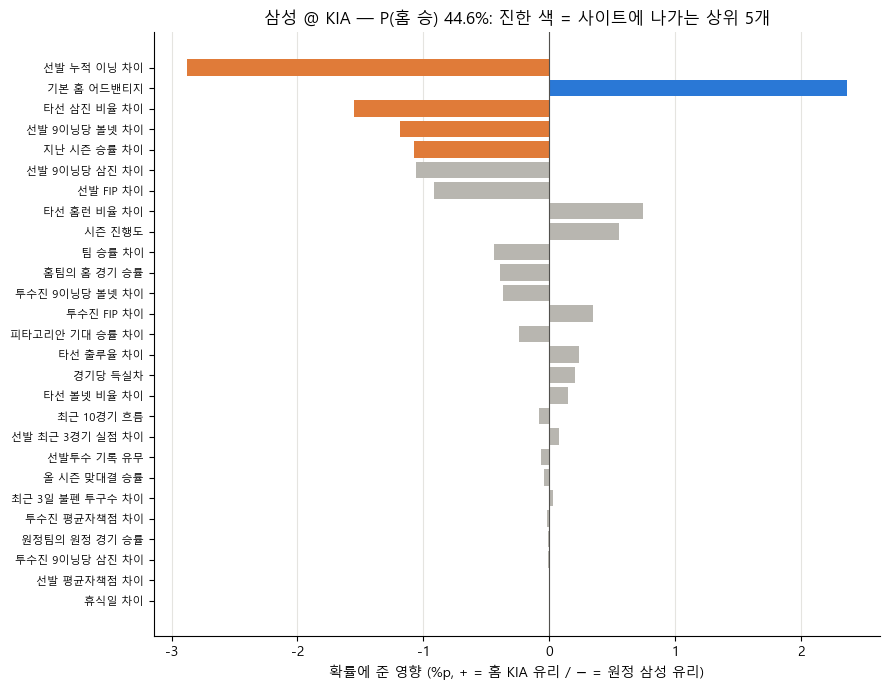

,요인,피처,피처 값(홈 − 원정),영향(%p)
0,선발 누적 이닝 차이,starter_ip_diff,-166.000,-2.9
1,기본 홈 어드밴티지,bias,NaN,2.4
2,타선 삼진 비율 차이,k_rate_diff,0.025,-1.5
3,선발 9이닝당 볼넷 차이,starter_bb9_diff,1.395,-1.2
4,지난 시즌 승률 차이,prev_season_diff,-0.057,-1.1


요인 27개 합 -5.6%p  vs  실제 확률 − 50% = -5.4%p (1차 근사라 조금 달라요)


In [5]:
pred = predict.predict_game(live, game, state, sp, starter_types=sp_types)   # latest.json의 경기 항목과 같은 dict
p = pred["home_win_prob"]
print(f"{TEAM_KO[HOME]}(홈) 승리 확률 {p:.1%} · {TEAM_KO[AWAY]}(원정) {1 - p:.1%}  — 모델 {live['version']}, "
      f"선발 기록 사용 starter_known={pred['starter_known']}")

f = features.game_features(game, state, sp)                # predict_game 안에서 만드는 것과 같은 피처
X = pd.DataFrame([{n: f[n] for n in live["features"]}])
p_raw = float(tw.predict_proba(live, X)[0])                # 반올림 전 확률 (요인 pp 계산에 쓰는 값)
pp = sorted(predict.factor_pp(live, X, p_raw), key=lambda kv: abs(kv[1]))   # 요인 27개 (작은 것 → 큰 것)
top5 = {d["name"] for d in pred["factors"]}

fig, ax = plt.subplots(figsize=(9, 7))
names, vals = [n for n, _ in pp], [v for _, v in pp]
colors = [(BLUE if v > 0 else ORANGE) if n in top5 else GRAY for n, v in pp]
ax.barh(names, vals, color=colors)
ax.axvline(0, color=INK, linewidth=0.8)
ax.grid(axis="x", color="#e5e4e0"); ax.grid(axis="y", visible=False)
ax.set(xlabel="확률에 준 영향 (%p, + = 홈 KIA 유리 / − = 원정 삼성 유리)",
       title=f"{TEAM_KO[AWAY]} @ {TEAM_KO[HOME]} — P(홈 승) {p:.1%}: 진한 색 = 사이트에 나가는 상위 5개")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

LABEL_TO_FEAT = {v: k for k, v in features.FACTOR_LABELS.items()}
display(pd.DataFrame([{"요인": d["name"], "피처": LABEL_TO_FEAT[d["name"]],
                       "피처 값(홈 − 원정)": None if LABEL_TO_FEAT[d["name"]] == "bias" else round(f[LABEL_TO_FEAT[d["name"]]], 3),
                       "영향(%p)": d["contribution_pp"]} for d in pred["factors"]]))
print(f"요인 27개 합 {sum(vals):+.1f}%p  vs  실제 확률 − 50% = {(p_raw - 0.5) * 100:+.1f}%p (1차 근사라 조금 달라요)")

**해석:** 모델은 KIA 승리 확률을 **44.6%**(삼성 55.4%)로 봐요. 홈 어드밴티지(+2.4%p)가 KIA 쪽으로 밀어 주지만, **선발 누적 이닝 차이**(최원태 2025+2026 249이닝 vs 시라카와 83이닝 → −166이닝, −2.9%p), KIA 타선의 높은 삼진 비율(−1.5), 시라카와의 볼넷(−1.2), 지난 시즌 승률(−1.1)이 삼성 쪽으로 더 세게 당겨요. 요인 27개의 합(−5.6%p)이 실제 차이(−5.4%p)와 거의 같아서 1차 근사가 잘 맞아요.

## 6. 전망(outlook) — 시리즈 몬테카를로

### 전망 카드
오늘 경기 하나의 확률만으로는 "그래서 누가 한국시리즈에 갈까?"를 알 수 없어요. 그래서 사이트에는 **전망(outlook)** 카드가 같이 나가요. `simulate.outlook_for`가 날짜를 보고 종류를 골라요.
- 정규시즌 날짜 → `playoff_race`: 10팀 각각의 가을야구(5위 안) 진출 확률 (7번 되감기에서 봐요)
- 포스트시즌 날짜이고 진행 중인 시리즈가 있으면 → `series`: 그 시리즈의 승리 확률 (오늘)
- 그 밖 → `next_game`: 다음 경기 날짜만

### 몬테카를로 시뮬레이션이란?
플레이오프는 5판 3선승이고, 지금 **1승 1패**라 최대 3경기가 남았어요. 남은 경기마다 "삼성이 이길 확률"을 알면, 컴퓨터로 **주사위를 굴리듯** 남은 경기를 가상으로 치러 볼 수 있어요. 이걸 **1만 번**(`N_SIMS`) 반복해 "삼성이 시리즈를 이긴 횟수 ÷ 1만"을 시리즈 승리 확률로 써요. 이렇게 "많이 굴려서 세는" 방법을 몬테카를로라고 불러요(카지노로 유명한 도시 이름이에요). 난수 시드를 고정해서(`SEED = 42`) 같은 입력이면 항상 같은 숫자가 나와요.

경기마다 확률은 이렇게 정해요(스펙 §8).
- **오늘 3차전:** 예고 선발을 아는 **승패 모델**의 확률, 즉 5번의 예측 그대로예요. 파이프라인은 `outlook_for(..., today_probs={경기 id: 반올림 전 P(홈 승)})`로 이 값을 넘기고(`predict.raw_prob` — `latest.json`의 `home_win_prob`가 되기 전 값), 카드의 `today_game_prob_source`에 `"win_model (starter-inclusive)"`라고 적어요.
- **4·5차전:** 선발을 아직 모르니까 **선발 없는 팀 모델**(`team-2026`)로 내요.

상태는 **오늘 아침 상태로 고정**해요(가상 경기 결과로 팀 기록을 다시 계산하지 않아요).

**출력 보는 법:** 파이프라인과 똑같이 기본 설정(1만 번, 시드 42)으로 낸 전망 카드예요. `wins`·`win_prob`·`most_common_result`는 모두 `teams`의 순서(삼성, KIA) 기준이에요.

In [6]:
PS = simulate.load_postseason(SEASON)                      # config/postseason.yaml의 2026 대진표
TODAY_PROBS = {GID: predict.raw_prob(live, game, state, sp)}   # 오늘 경기의 반올림 전 P(홈 승) — run_pipeline이 넘기는 값
print(f"오늘 경기 P(홈 승) 반올림 전 {TODAY_PROBS[GID]:.6f} = 5번의 p_raw?: {TODAY_PROBS[GID] == p_raw}")
outlook = simulate.outlook_for(SEASON, TARGET, games, state=state, team_bundle=team_model, ps_config=PS,
                               today_probs=TODAY_PROBS)    # 기본 1만 번, 시드 42
display(pd.Series(outlook, name="outlook").to_frame())
t0_, t1_ = outlook["teams"]
print(f"{outlook['name']} {TEAM_KO[t0_]} {outlook['wins'][0]}승 – {TEAM_KO[t1_]} {outlook['wins'][1]}승 → "
      f"시리즈 승리 확률 {TEAM_KO[t0_]} {outlook['win_prob'][0]:.1%} · {TEAM_KO[t1_]} {outlook['win_prob'][1]:.1%}, "
      f"가장 흔한 결말 {outlook['most_common_result']} ({TEAM_KO[t0_]} 기준)")

오늘 경기 P(홈 승) 반올림 전 0.446374 = 5번의 p_raw?: True


,outlook
type,series
as_of,2026-10-29
name,플레이오프
best_of,5
teams,"[SS, HT]"
head_start,"[0, 0]"
wins,"[1, 1]"
win_prob,"[0.5579, 0.4421]"
most_common_result,3-2
goes_distance_prob,0.5083


플레이오프 삼성 1승 – KIA 1승 → 시리즈 승리 확률 삼성 55.8% · KIA 44.2%, 가장 흔한 결말 3-2 (삼성 기준)


**해석:** 오늘 경기 전 기준 삼성의 시리즈 승리 확률은 **55.8%**(KIA 44.2%), 가장 흔한 결말은 삼성 3승 2패(`3-2`), 5차전까지 갈 확률은 50.8%예요. 카드의 `today_game_prob_source`가 `win_model (starter-inclusive)`이니, 오늘 3차전은 5번의 예측(삼성 55.4%) 그대로 굴렸다는 뜻이에요. 남은 경기를 어떤 확률로 굴렸는지는 바로 다음 칸에서 열어 봐요.

### 카드 안을 열어 보기: 남은 경기의 확률 → `simulate.series`
`outlook_for`가 안에서 하는 일을 한 단계씩 따라가요.
1. `simulate.active_series`가 대진표에서 진행 중인 시리즈를 찾고, `simulate.series_record`가 어제까지의 맞대결로 전적(1-1)을 세요. 10-25 경기는 취소라 전적에 들어가지 않고, 같은 순번(1차전)이 다음 날 다시 치러졌다고 봐요. (와일드카드처럼 1승을 안고 시작하는 시리즈는 대진표의 `head_start`가 전적에 처음부터 더해져요. 플레이오프는 `[0, 0]`이에요.)
2. `simulate.left_homes`가 대진표의 홈 순서(삼성·삼성·KIA·KIA·삼성)에서 이미 치른 2경기를 건너뛰어 남은 3경기의 홈을 내요.
3. `simulate.series_probs`가 남은 경기마다 팀 모델로 P(홈 승)을 내고 **삼성 기준**으로 뒤집은 뒤, **첫 칸(오늘 3차전)만** 승패 모델 확률(`TODAY_PROBS`)로 바꿔요(오늘 경기의 실제 홈이 그 칸의 홈과 같을 때만). 날짜는 모두 오늘로 둬요(미래 날짜를 넣으면 "휴식일" 피처가 날짜만으로 커지니까요).
4. `simulate.series(5, (1, 1), 홈 목록, 삼성 승률 목록)`이 1만 번 굴려요.

모두 `outlook_for`가 안에서 부르는 바로 그 함수들이에요 — 노트북에서 식을 새로 짜지 않아요.

**출력 보는 법:** 남은 3경기의 홈, "오늘 경기도 팀 모델로 굴렸다면"의 삼성 승리 확률(비교용), 카드가 실제로 쓴 삼성 승리 확률과 그 출처예요. 아래 줄은 `series`를 직접 부른 결과가 카드와 같은지(`True`), 그리고 오늘 경기도 팀 모델로 굴렸을 때의 시리즈 확률이에요.

In [7]:
s = simulate.active_series(SEASON, TARGET, games, PS)     # 진행 중인 시리즈 (플레이오프)
w0, w1, draws = simulate.series_record(games, s, TARGET)  # 어제까지 전적 (삼성 승, KIA 승, 무승부) — head_start 포함
need, n_left = s["best_of"] // 2 + 1, s["best_of"] - w0 - w1
left_homes = simulate.left_homes(s, w0, w1, draws)        # 남은 경기의 홈 (outlook_for와 같은 함수)
_, p_t0, source = simulate.series_probs(s, TARGET, games, state, team_model, TODAY_PROBS)   # 카드가 쓰는 P(삼성 승)
_, p_t0_team, _ = simulate.series_probs(s, TARGET, games, state, team_model)               # 오늘 경기도 팀 모델이었다면 (비교용)
display(pd.DataFrame({"차전": range(w0 + w1 + 1, w0 + w1 + 1 + n_left), "홈": [TEAM_KO[h] for h in left_homes],
                      f"팀 모델만 P({TEAM_KO[t0_]} 승)": np.round(p_t0_team, 4),
                      f"카드 입력 P({TEAM_KO[t0_]} 승)": np.round(p_t0, 4),
                      "출처": ["승패 모델 (예고 선발)" if i == 0 and source == simulate.TODAY_SOURCE_WIN else "팀 모델"
                               for i in range(n_left)]}).set_index("차전"))

homes_tag = ["team0" if h == t0_ else "team1" for h in left_homes]
res = simulate.series(s["best_of"], (w0, w1), homes_tag, p_t0)   # 기본값: n_sims = 10,000, seed = 42
res_team = simulate.series(s["best_of"], (w0, w1), homes_tag, p_t0_team)
print(f"simulate.series → {res}")
print(f"카드와 같나요?: {res['win_prob'] == outlook['win_prob'] and res['most_common_result'] == outlook['most_common_result']}"
      f" · 카드의 today_game_prob_source = {outlook['today_game_prob_source']!r}")
print(f"(비교) 오늘 경기도 팀 모델로 굴렸다면: {TEAM_KO[t0_]} {res_team['win_prob'][0]:.1%}, 가장 흔한 결말 {res_team['most_common_result']}")

,홈,팀 모델만 P(삼성 승),카드 입력 P(삼성 승),출처
차전,,,,
3,KIA,0.4974,0.5536,승패 모델 (예고 선발)
4,KIA,0.4974,0.4974,팀 모델
5,삼성,0.5629,0.5629,팀 모델


simulate.series → {'win_prob': [0.5579, 0.4421], 'most_common_result': '3-2', 'goes_distance_prob': 0.5083, 'games_remaining_max': 3}
카드와 같나요?: True · 카드의 today_game_prob_source = 'win_model (starter-inclusive)'
(비교) 오늘 경기도 팀 모델로 굴렸다면: 삼성 52.8%, 가장 흔한 결말 3-2


**해석:** 오늘 3차전(KIA 홈)은 예고 선발을 아는 승패 모델의 삼성 55.4%, 선발을 모르는 4차전(KIA 홈)은 팀 모델의 삼성 49.7%, 5차전(삼성 홈)은 56.3%로 굴려요. 팀 모델만 쓰면 3·4차전 확률이 똑같은데(49.7%), 상태와 날짜를 오늘로 고정했기 때문이에요. 오늘 경기에 선발 정보를 쓰느냐에 따라 시리즈 확률이 3%p 달라져요 — 오늘 경기도 팀 모델로 굴렸다면 삼성 52.8%였어요. 직접 부른 `series`가 카드와 같은 숫자를 내요(`True`).

### 결말의 분포 — 시뮬레이션 vs 정확한 계산
`series`는 확률과 "가장 흔한 결말" 하나만 돌려줘요. 결말 전체의 분포를 보려면 1만 번의 가상 시리즈를 직접 세면 돼요. `series`와 같은 시드·같은 순서로 난수를 뽑으면 **같은 1만 번**이 나와요(그래서 삼성 승리 비율이 위 카드와 정확히 같아야 해요).

남은 경기가 3개뿐이라, 사실 이 문제는 **정확히** 계산할 수도 있어요. 3경기의 승패 조합은 2³ = 8가지뿐이니까, 각 조합의 확률(경기 확률의 곱)을 그 조합의 최종 전적에 더하면 돼요. 몬테카를로가 정확한 값에 얼마나 가까운지 비교할 수 있죠. (정규시즌은 남은 경기가 수백 개라 조합이 너무 많아서 시뮬레이션이 꼭 필요해요.)

**출력 보는 법:** 막대 = 1만 번 시뮬레이션의 비율, 검은 점 = 정확한 확률이에요. 파랑은 삼성이 이기는 결말, 주황은 KIA가 이기는 결말이에요.

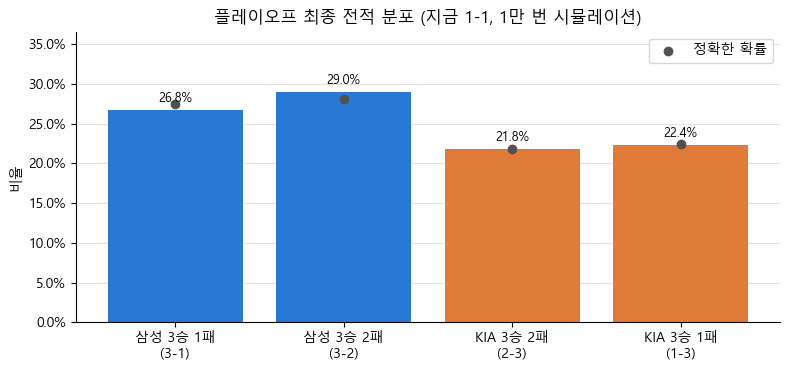

삼성 시리즈 승리: 시뮬레이션 0.5579 (= 카드 0.5579: True) · 정확한 값 0.5570
가장 흔한 결말: 시뮬레이션 (3, 2) · 정확한 값 (3, 2)


In [8]:
rng = np.random.default_rng(simulate.SEED)                 # series와 같은 시드 → 같은 난수
t0_win = rng.random((simulate.N_SIMS, n_left)) < np.asarray(p_t0)   # [1만, 남은 경기]: 삼성이 이겼나
c0, c1 = w0 + np.cumsum(t0_win, axis=1), w1 + np.cumsum(~t0_win, axis=1)   # 경기마다 누적 승수
end = ((c0 >= need) | (c1 >= need)).argmax(axis=1)          # 시리즈가 끝난 경기
idx = np.arange(simulate.N_SIMS)
sim = Counter(zip(c0[idx, end].tolist(), c1[idx, end].tolist()))   # 최종 전적별 횟수

exact = Counter()                                          # 8가지 조합을 모두 따져 정확한 확률
for outcome in product((1, 0), repeat=n_left):            # 1 = 삼성 승, 0 = KIA 승 (끝난 뒤 경기도 일단 정해 둠)
    prob = float(np.prod([q if won else 1 - q for won, q in zip(outcome, p_t0)]))
    a, b = w0, w1
    for won in outcome:
        if a >= need or b >= need:
            break                                          # 이미 끝났으면 나머지 경기는 치르지 않음
        a, b = a + won, b + 1 - won
    exact[(a, b)] += prob

order = sorted(exact, key=lambda k: (-(k[0] >= need), k[1] if k[0] >= need else -k[0]))   # 삼성 3-1, 3-2, KIA 2-3, 1-3 순
labels = [f"{TEAM_KO[t0_] if a >= need else TEAM_KO[t1_]} {max(a, b)}승 {min(a, b)}패\n({a}-{b})" for a, b in order]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(labels, [sim[k] / simulate.N_SIMS for k in order], color=[BLUE if k[0] >= need else ORANGE for k in order])
ax.scatter(labels, [exact[k] for k in order], color=INK, zorder=3, label="정확한 확률")
for x, k in enumerate(order):
    ax.text(x, sim[k] / simulate.N_SIMS + 0.01, f"{sim[k] / simulate.N_SIMS:.1%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(ylim=(0, max(exact.values()) * 1.3), ylabel="비율", title=f"{s['name']} 최종 전적 분포 (지금 {w0}-{w1}, 1만 번 시뮬레이션)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

mc_p0 = sum(v for (a, b), v in sim.items() if a >= need) / simulate.N_SIMS
ex_p0 = sum(v for (a, b), v in exact.items() if a >= need)
print(f"{TEAM_KO[t0_]} 시리즈 승리: 시뮬레이션 {mc_p0:.4f} (= 카드 {outlook['win_prob'][0]}: {mc_p0 == outlook['win_prob'][0]}) · 정확한 값 {ex_p0:.4f}")
print(f"가장 흔한 결말: 시뮬레이션 {sim.most_common(1)[0][0]} · 정확한 값 {max(exact, key=exact.get)}")

**해석:** 네 가지 결말이 22~29%로 고르게 퍼져 있고, 삼성이 조금 앞선 시리즈예요. 가장 흔한 결말이 삼성 3승 2패(29.0%)인 건 절반(50.8%)이 5차전까지 가고 그 5차전이 삼성 홈(56%)이기 때문이에요. 시뮬레이션(55.79%)과 정확한 값(55.70%)의 차이는 0.1%p로, 1만 번 굴렸을 때의 자연스러운 흔들림(약 ±0.5%p) 안이에요.

### 몇 번 굴려야 충분할까?
몬테카를로의 답은 굴린 횟수에 따라 흔들려요. 같은 횟수로 **시드만 20번 바꿔** 돌려 보면 그 흔들림의 크기를 볼 수 있어요. (이 그림만 설명용으로 횟수를 바꿔요. 위의 카드 숫자는 파이프라인과 같은 기본값 1만 번이에요.)

**출력 보는 법:** 점 = 시드 20개의 평균, 막대 = 20개의 최솟값~최댓값, 점선 = 정확한 값이에요. 가로축은 로그 눈금이에요.

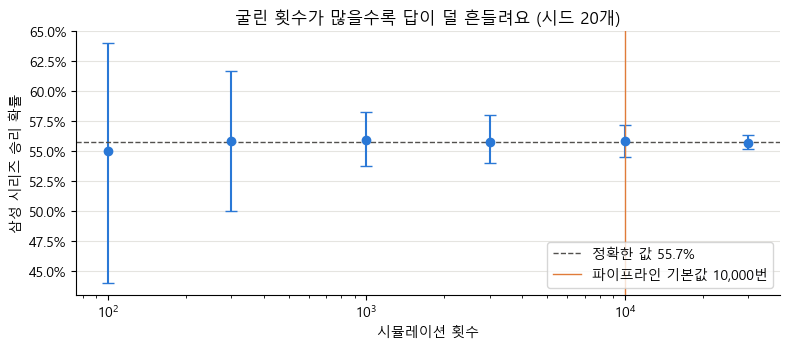

,100,300,1000,3000,10000,30000
최대 − 최소 (20개 시드),0.2,0.1167,0.045,0.0403,0.0261,0.0116


In [9]:
sizes = [100, 300, 1_000, 3_000, 10_000, 30_000]
spread = pd.DataFrame({n: [simulate.series(s["best_of"], (w0, w1), homes_tag, p_t0, n_sims=n, seed=k)["win_prob"][0]
                           for k in range(20)] for n in sizes})
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(sizes, spread.mean(), yerr=[spread.mean() - spread.min(), spread.max() - spread.mean()],
            fmt="o", color=BLUE, capsize=4)
ax.axhline(ex_p0, color=INK, linestyle="--", linewidth=1, label=f"정확한 값 {ex_p0:.1%}")
ax.axvline(simulate.N_SIMS, color=ORANGE, linewidth=1, label=f"파이프라인 기본값 {simulate.N_SIMS:,}번")
ax.set_xscale("log")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel="시뮬레이션 횟수", ylabel=f"{TEAM_KO[t0_]} 시리즈 승리 확률", title="굴린 횟수가 많을수록 답이 덜 흔들려요 (시드 20개)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display((spread.max() - spread.min()).rename("최대 − 최소 (20개 시드)").to_frame().T.round(4))

**해석:** 100번만 굴리면 시드에 따라 44%~64%로 20%p나 흔들리지만, 1만 번이면 흔들림이 2.6%p 폭 안으로 줄어요. 흔들림은 횟수의 제곱근에 반비례해서, 절반으로 줄이려면 4배를 더 굴려야 해요. 1만 번은 순식간에 끝나면서 퍼센트 첫 자리가 거의 안정되는 타협점이에요.

## 7. 되감기 — 2026-09-01 하루와 시즌 누적 적중률

### 되감기(rewind) 모드란?
비시즌에는 "오늘 경기"가 없어서 사이트가 텅 비어요. 그래서 사이트는 **지난 정규시즌을 하루씩 되감아** 보여 줘요. 하루치 파일(`data/public/rewind/2026/{날짜}.json`)에는 "그날 아침 시점의 정보만으로 모델이 한 예측 + 실제 결과 + 그날의 가을야구 전망"이 들어 있어요. `scripts/build_rewind.py`가 시즌 전체(165일)를 만들어요.

라이브와 다른 점 세 가지:
- **모델:** 평가용 `report-2026`(2015~2024로만 학습). 2026은 학습에 안 쓴 시험 시즌이라, 되감기 적중률 = 03번 노트북의 **시험 정확도**예요.
- **선발:** 예고 선발이 아니라 박스스코어의 **실제 선발**을 써요(학습 피처와 같은 선발). 지난 경기의 예고 선발은 저장돼 있지 않기 때문이에요.
- **누수 방지:** 그날의 상태에는 **전날까지** 끝난 경기만 들어가요. 그날 결과는 `result` 칸에만 있어요.

**출력 보는 법:** 위 표는 2026-09-01의 경기 5개(예측한 쪽 `pick`, 실제 점수, 적중 여부), 아래 표는 그날 아침의 가을야구 전망(`playoff_race`, 10팀 × 1만 번 시뮬레이션)이에요.

In [10]:
REWIND_DAY = "2026-09-01"
day = json.loads((PUBLIC / "rewind" / str(SEASON) / f"{REWIND_DAY}.json").read_text(encoding="utf-8"))
print(f"{day['date']} · 모델 {day['model_version']} · 전망 모델 {day['team_model_version']} · 선발 = {day['starter_source']}")
display(pd.DataFrame([{"경기": f"{TEAM_KO[g['away']['code']]} @ {TEAM_KO[g['home']['code']]}",
                       "원정 선발": g["away"]["starter"]["name"], "홈 선발": g["home"]["starter"]["name"],
                       "P(홈 승)": g["home_win_prob"], "예측": TEAM_KO[g["home" if g["result"]["pick"] == "HOME" else "away"]["code"]],
                       "점수(원정-홈)": f"{g['result']['away_score']}-{g['result']['home_score']}",
                       "적중": g["result"]["correct"]} for g in day["games"]]).set_index("경기"))

race = day["outlook"]["teams"]
display(pd.DataFrame([{"팀": TEAM_KO[c], "승-패": f"{v['wins']}-{v['losses']}", "현재 순위": v["rank_now"],
                       "가을야구 확률": f"{v['playoff_prob']:.1%}", "기대 최종 승수": round(v["exp_wins"], 1)}
                      for c, v in sorted(race.items(), key=lambda kv: kv[1]["rank_now"])]).set_index("팀"))

2026-09-01 · 모델 report-2026 · 전망 모델 team-2026 · 선발 = actual (boxscore pitching order 1)


,원정 선발,홈 선발,P(홈 승),예측,점수(원정-홈),적중
경기,,,,,,
한화 @ KT,White,Daniel,0.5290,KT,1-6,True
KIA @ NC,Naile,Koo Chang-mo,0.4544,KIA,2-7,False
LG @ 두산,Im Chan-kyu,Logue,0.4838,LG,3-1,True
롯데 @ 삼성,Rodríguez,Voth,0.5954,삼성,0-3,True
SSG @ 키움,Choi Min-jun,Alcántara,0.5045,키움,4-0,False


,승-패,현재 순위,가을야구 확률,기대 최종 승수
팀,,,,
삼성,68-44,1,100.0%,84.1
KT,66-43,2,100.0%,82.8
KIA,63-50,3,99.5%,77.6
LG,63-51,4,99.7%,78.5
두산,61-52,5,96.6%,74.0
NC,51-58,6,3.0%,66.9
롯데,50-61,7,0.8%,65.6
한화,49-61,8,0.5%,64.9
SSG,48-65,9,0.0%,61.4


**해석:** 9월 1일에는 5경기 중 3경기를 맞혔어요. 50%에 가까운 경기(키움 50.5%, 두산 48.4%)가 많아 하루 단위 적중은 운이 크게 작용해요. 그날 아침 전망으로는 상위 5팀(삼성·KT·KIA·LG·두산)이 모두 96% 이상, 6위 NC는 3%로 가을야구 판도가 사실상 정해져 있었고, 실제로 이 다섯 팀이 포스트시즌에 나갔어요.

### 시즌 누적 적중률
`index.json`에는 날짜마다 경기 수·적중 수가 있어요. 개막일부터 그날까지 적중 수를 더해 나누면 **누적 적중률**이 돼요. 시즌 초에는 경기가 적어 크게 출렁이고, 경기가 쌓일수록 한 값으로 모여요.

**출력 보는 법:** 파란 선 = 누적 적중률, 회색 점선 = 비교 기준(늘 홈팀 / 승률 높은 팀을 고르는 단순 규칙, 03번), 주황 점 = 위에서 본 2026-09-01이에요.

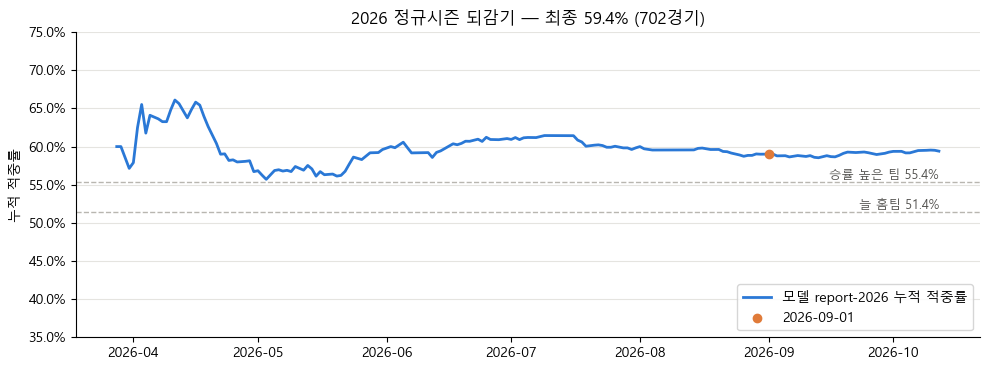

되감기 날짜 165일 · 적중 417 / 702 = 0.594
03번의 시험 정확도(model_report.json) 0.5940 (n = 702) → 같나요?: True
2026-09-01 시점 누적 적중률 59.0%


In [11]:
index = json.loads((PUBLIC / "rewind" / str(SEASON) / "index.json").read_text(encoding="utf-8"))
report = json.loads((PUBLIC / "model_report.json").read_text(encoding="utf-8"))
idx_df = pd.DataFrame(index["dates"]).assign(date=lambda d: pd.to_datetime(d["date"]))
idx_df["누적 적중률"] = idx_df["correct"].cumsum() / idx_df["decided"].cumsum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(idx_df["date"], idx_df["누적 적중률"], color=BLUE, linewidth=2, label="모델 report-2026 누적 적중률")
for key, name in [("home_always", "늘 홈팀"), ("better_win_pct", "승률 높은 팀")]:
    ax.axhline(report["baselines"]["test"][key], color=GRAY, linestyle="--", linewidth=1)
    ax.text(idx_df["date"].iloc[-1], report["baselines"]["test"][key], f"{name} {report['baselines']['test'][key]:.1%}",
            ha="right", va="bottom", fontsize=9, color=INK)
mark = idx_df[idx_df["date"] == pd.Timestamp(REWIND_DAY)]
ax.scatter(mark["date"], mark["누적 적중률"], color=ORANGE, zorder=3, label=f"{REWIND_DAY}")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(ylim=(0.35, 0.75), ylabel="누적 적중률", title=f"2026 정규시즌 되감기 — 최종 {index['accuracy']:.1%} ({index['n_decided']}경기)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

test_acc = report["models"][report["selected"]]["test"]["accuracy"]
print(f"되감기 날짜 {len(index['dates'])}일 · 적중 {sum(d['correct'] for d in index['dates'])} / {index['n_decided']} = {index['accuracy']}")
print(f"03번의 시험 정확도(model_report.json) {test_acc:.4f} (n = {report['models'][report['selected']]['test']['n']}) → 같나요?: "
      f"{index['accuracy'] == round(test_acc, 4) and index['n_decided'] == report['models'][report['selected']]['test']['n']}")
print(f"{REWIND_DAY} 시점 누적 적중률 {mark['누적 적중률'].iloc[0]:.1%}")

**해석:** 3~5월에는 하루 5경기씩 더해지며 56%~66%로 크게 출렁였지만, 6월 이후로는 59~61%에서 거의 움직이지 않아요. 최종 **59.4%(417 / 702)**는 03번의 시험 정확도와 정확히 같아요(`True`) — 같은 모델·같은 702경기·같은 판정 규칙이라서예요. 시즌 내내 단순 규칙(늘 홈팀 51.4%, 승률 높은 팀 55.4%)보다 위에 있어요.

## 8. 라이브 기록 — `history.csv`

되감기는 "지난 시즌을 다시 돌려 본" 결과예요. 그런데 진짜 실력은 **경기 전에 공개하고 나중에 채점받은** 예측으로 봐야 해요. 파이프라인은 경기 전 예측을 `history.csv`에 한 줄씩 쓰고(`status = SCHEDULED`), 다음 실행 때 결과가 나오면 `winner`와 `correct`(1 = 적중, 0 = 빗나감)를 채워요(정산). 한 번 정산된 줄은 다시 바꾸지 않아요.

**출력 보는 법:** 위 표는 `history.csv` 전체, 아래 표는 모델 버전별 예측 수·정산된 경기 수·적중률이에요. 정산된 경기가 없으면 적중률은 빈칸(NaN)이에요.

In [12]:
hist = pd.read_csv(PUBLIC / "history.csv", dtype={"game_id": str})
display(hist)
by_version = hist.groupby("model_version").agg(예측=("game_id", "size"), 정산=("correct", "count"), 적중=("correct", "sum"))
by_version["적중률"] = by_version["적중"] / by_version["정산"].where(by_version["정산"] > 0)
display(by_version)
print(f"라이브 기록 {len(hist)}줄 · 기간 {hist['date'].min()} ~ {hist['date'].max()} · 정산된 경기 {int(hist['correct'].notna().sum())}개")

,date,game_id,home,away,home_win_prob,model_version,predicted_at,status,winner,correct
0,2026-10-29,14050,HT,SS,0.4464,v0.2,2026-10-29T14:40:20+09:00,SCHEDULED,NaN,NaN


,예측,정산,적중,적중률
model_version,,,,
v0.2,1,0,0.0,NaN


라이브 기록 1줄 · 기간 2026-10-29 ~ 2026-10-29 · 정산된 경기 0개


**해석:** 이 노트북을 실행한 시점의 라이브 기록은 **1줄**(오늘 2026-10-29 경기, 아직 정산 전)뿐이라 라이브 적중률은 아직 말할 수 없어요. 자동화를 정규시즌이 끝난 10월 말에 시작했기 때문이에요. 그래서 지금 모델의 실력은 7번 되감기(702경기, 59.4%)로 판단하고, 라이브 기록은 남은 포스트시즌과 다음 시즌부터 쌓여요.

## 9. 동일성 확인 — 노트북 = 파이프라인

마지막으로, 이 노트북이 한 칸씩 만든 결과가 **실제 파이프라인 코드가 만드는 파일과 완전히 같은지** 확인해요.
1. **오늘 예측:** `run_pipeline.run(2026-10-29, fetch=False)`를 **임시 폴더**에 돌려요(네트워크 없이 저장된 데이터만으로 — 2번에서 말한 "수집 건너뛰기"). 임시 폴더에 생긴 `latest.json`의 경기 항목이 5번의 `pred`와, `outlook`이 6번의 카드와 **한 글자도 다르지 않아야** 해요. 파이프라인은 경기 항목에 `status_note`(경기 메모) 칸을 하나 더 붙이니까, 비교할 때 같은 칸을 붙여요. 저장소의 진짜 `data/public/`은 건드리지 않아요.
2. **되감기:** `build_rewind.py`와 같은 입력(평가 모델 `report-2026`, 팀 모델, 2025 투수 유형, 대진표)으로 `rewind.day_payload(2026, "2026-09-01")`를 다시 만들어, 커밋된 `2026-09-01.json`과 비교해요. 실행할 때마다 달라지는 `generated_at`(만든 시각)·`commit_sha`(커밋)만 빼요.

**출력 보는 법:** ✅ 줄이 나오면 같아요. 다르면 ❌와 함께 셀이 오류로 멈춰요. 맨 아래 줄은 노트북 전체 실행 시간이에요.

In [13]:
META = {"generated_at": f"{TARGET}T17:07:00+09:00", "commit_sha": None, "run_url": None}   # 실행 정보 (비교에는 안 써요)
with tempfile.TemporaryDirectory() as tmp:
    out = run_pipeline.run(date.fromisoformat(TARGET), data_dir=Path(tmp), model_path=LIVE_PKL, meta=META, fetch=False,
                           clusters_path=CLUSTERS_PKL, team_path=TEAM_PKL)   # 발행 파일만 tmp/public/에 써요
    latest = json.loads((Path(tmp) / "public" / "latest.json").read_text(encoding="utf-8"))
    status = json.loads((Path(tmp) / "public" / "status.json").read_text(encoding="utf-8"))
print(f"run() → {out} · status mode {status['mode']} · 수집 경고 {status['collect_errors']} · latest 모델 {latest['model_version']}")

mine_game = json.loads(json.dumps({**pred, "status_note": game.get("status_note")}))   # JSON으로 한 번 옮겨 파일과 같은 모양으로
pipe_game = next(g for g in latest["games"] if g["game_id"] == GID)
same_game = mine_game == pipe_game
same_outlook = json.loads(json.dumps(outlook)) == latest["outlook"]
print(f"5번 pred == latest.json의 경기 {GID}?: {same_game}  (P(홈 승) {pipe_game['home_win_prob']}, 원정 선발 유형 {pipe_game['away']['starter']['type']})")
print(f"6번 outlook == latest.json의 outlook?: {same_outlook}  (win_prob {latest['outlook']['win_prob']}, 가장 흔한 결말 {latest['outlook']['most_common_result']})")

committed_day = json.loads((PUBLIC / "rewind" / str(SEASON) / f"{REWIND_DAY}.json").read_text(encoding="utf-8"))
regen_day = rewind.day_payload(SEASON, REWIND_DAY, games=games, boxscores=raw_store.load_boxscores(SEASON),
                               bundle=report_model, team_bundle=team_model, starter_types=sp_types,
                               meta={"generated_at": None, "commit_sha": None, "run_url": None}, ps_config=PS)
IGNORE = ("generated_at", "commit_sha")                    # 실행마다 달라지는 칸
same_rewind = ({k: v for k, v in json.loads(json.dumps(regen_day)).items() if k not in IGNORE}
               == {k: v for k, v in committed_day.items() if k not in IGNORE})
print(f"다시 만든 되감기 {REWIND_DAY} == 커밋된 파일 (generated_at·commit_sha 제외)?: {same_rewind}  "
      f"(경기 {len(regen_day['games'])}개, 전망 {regen_day['outlook']['type']})")

if same_game and same_outlook and same_rewind:
    print("✅ 같아요! 노트북의 예측·전망 = 파이프라인의 latest.json, 다시 만든 되감기 = 커밋된 되감기 파일")
else:
    print("❌ 달라요! 노트북과 파이프라인이 다른 입력이나 코드를 쓰고 있어요")
assert same_game and same_outlook and same_rewind
print(f"노트북 전체 실행 시간: {time.time() - T0:.1f}초")

run() → {'games_today': 1, 'settled': 0} · status mode live · 수집 경고 [] · latest 모델 v0.2
5번 pred == latest.json의 경기 14050?: True  (P(홈 승) 0.4464, 원정 선발 유형 {'id': 0, 'name': '선발형'})
6번 outlook == latest.json의 outlook?: True  (win_prob [0.5579, 0.4421], 가장 흔한 결말 3-2)


다시 만든 되감기 2026-09-01 == 커밋된 파일 (generated_at·commit_sha 제외)?: True  (경기 5개, 전망 playoff_race)
✅ 같아요! 노트북의 예측·전망 = 파이프라인의 latest.json, 다시 만든 되감기 = 커밋된 되감기 파일
노트북 전체 실행 시간: 4.5초


**해석:** 세 가지 모두 같아요(`True`). 노트북의 예측 항목과 전망 카드는 `run_pipeline.run`이 쓴 `latest.json`과 똑같고(P(홈 승) 0.4464, 시리즈 [0.5579, 0.4421], `3-2` — 파이프라인도 오늘 경기의 반올림 전 확률을 `today_probs`로 넘기니까 6번과 같은 카드가 나와요), 같은 입력으로 다시 만든 되감기 하루치도 커밋본과 같아요. 수집 경고도 없어요(`[]`). 이 노트북의 설명이 곧 Actions가 매일 돌리는 과정이라는 증거예요.

## 10. 마무리 — 배운 점과 한계

### 오늘 확인한 것
- 저장된 일정·예고 선발만으로(네트워크 없이) 2026-10-29 플레이오프 3차전을 다시 예측했어요: **KIA 승리 44.6%**(삼성 55.4%). 가장 큰 요인은 선발 누적 이닝 차이(−2.9%p)와 홈 어드밴티지(+2.4%p)예요.
- 선발 블록에는 직전 시즌 유형이 붙어요: 최원태 **선발형**, 시라카와는 2025 기록이 없어 유형 없음.
- 전망: 1승 1패에서 **삼성 시리즈 승리 55.8%**, 가장 흔한 결말 **3-2**. 오늘 3차전은 선발 포함 확률(삼성 55.4%)로, 4·5차전은 팀 모델로 굴렸어요. 1만 번 몬테카를로가 정확한 계산(55.7%)과 0.1%p 차이였어요.
- 되감기: 2026 정규시즌을 하루씩 되감은 누적 적중률 **59.4%(702경기)** = 03번의 시험 정확도.
- 노트북 결과 = `run_pipeline.run(fetch=False)`의 `latest.json`, 다시 만든 되감기 = 커밋본.

### 한계 (솔직하게)
- **예고 선발이 바뀌면 늦어요.** 마지막 실행은 17:07이고 경기는 18:30이에요. 17:07 뒤에 선발이 바뀌면(부상·컨디션) 공개된 예측은 바뀌기 전 선발로 남아요. 09:07 실행 때 선발이 아직 발표 전이면 그 실행은 선발 없이(`starter_known = False`) 예측해요. 그리고 학습은 실제 선발로 했는데 라이브는 예고 선발을 쓰니, 둘이 다른 날은 그만큼 어긋나요.
- **시뮬레이션은 오늘 상태를 고정해요.** 남은 경기는 모두 오늘 아침 상태·오늘 날짜로 확률을 내요. 선발을 아는 건 오늘 경기뿐이고, 4·5차전은 선발 없는 팀 모델이라 선발 로테이션(누가 4·5차전에 나올지)을 반영하지 않아요. 연승 흐름, 휴식일·불펜 피로도 반영하지 않아요.
- **포스트시즌 보정이 없어요.** 모델은 정규시즌 경기로만 학습했고, 상태에도 정규시즌 경기만 쌓아요. 그래서 1·2차전 결과는 시리즈 전적에만 들어가고 팀 기록·최근 10경기·휴식일(둘 다 17일)에는 들어가지 않아요. 에이스 몰아 쓰기, 불펜 총력전 같은 단기전의 특성도 모델은 몰라요.
- **되감기는 실제 선발을 써요.** 지난 경기의 예고 선발은 저장돼 있지 않아서 되감기는 박스스코어의 실제 선발로 예측해요. 그래서 되감기 적중률(59.4%)은 "예고 선발이 틀릴 위험"이 없는, 라이브보다 살짝 유리한 조건의 숫자예요.
- **라이브 기록이 짧아요.** `history.csv`는 10월 말에 시작해서, 작성 시점에는 아직 정산된 경기가 없어요. 라이브 실력은 기록이 쌓여야 말할 수 있어요.

### 다음 이야기
- **5단계:** 이 노트북에서 본 `latest.json`(오늘 예측·전망), 되감기 파일, `history.csv`를 웹사이트 화면으로 보여 줘요.